# Bias maps: where does neglecting hyperillumination bias $A_B$ and $F$?

The noiseless `hyperillum` truth fitted with the point-source model, with $A_B$ only (`naive`, section 1) and with $A_B$ and $F$ (`naive_redist`, section 2; the truth has $F = 0$, so the fitted $F$ is itself a bias). Each section maps the bias over $(a/R_\star, T_{\rm eff})$ at a reference geometry, evaluates every planet of `PAPER_PLANETS` at its own geometry and noise, and fits one planet in several instruments.

In [1]:
import numpy as np
import os
import contextlib, io
import warnings
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given", category=UserWarning)   # loky replaces a worker that exits on its own (idle timeout or memory guard); the queued jobs still run, results unaffected
import matplotlib.pyplot as plt
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperphase.defaults import (DEFAULT_A, DEFAULT_A_B, DEFAULT_MAP_RP_RS, DEFAULT_N_BINS, DEFAULT_N_LA, DEFAULT_N_LO, DEFAULT_N_ORBITS, DEFAULT_U,
                                 DEFAULT_U_BOL)
from hyperphase.model import ConstantBandAlbedo, FittingConfig
from hyperphase.bias.detectors import instrument_cfg, instrument_key
from hyperphase.bias.fisher import VERDICT_NAIVE_OK, VERDICT_NEEDS_HI, VERDICT_NO_NOISE, VERDICT_UNCONSTRAINED
from hyperphase.bias.maps import bias_map_grid, false_F_map_grid, map_grid, reference_planet
from hyperphase.bias.tables import (FALSE_POSITIVE, instrument_depths, instrument_false_F, instrument_retrievals, NO_FALSE_POSITIVE, noise_cols,
                                    planet_bias_table, planet_false_F_table)
from hyperphase.plotting.bias import plot_false_F_bars, plot_instrument_retrievals, plot_planet_false_F_bars, plot_planet_retrievals
from hyperphase.plotting.maps import plot_bias_maps, plot_false_F_map
from hyperphase.plotting.style import set_plot_style
from hyperphase.targets import hi_planets_by_name
from hyperphase.bands import JWST_BANDS
from hyperphase.noise import rms_1min_pandexo_sample
from hyperphase.paper import JWST_RETRIEVALS, PAPER_PLANETS

# Exoplanet Archive (to populate bias map)
AGG = os.path.join(os.path.dirname(os.path.abspath('')), 'inputs', 'exoplanet_archive', 'NASAExoArchive_2026-08-21_aggregate_short.csv')

In [2]:
# Reference geometry of the maps. Each map sweeps a/Rs and one more parameter; everything else is held at these values.
incl_ref  = 90.     # [deg] central transit, so every map cell occults
rp_rs_ref = DEFAULT_MAP_RP_RS   # Rp/Rs held fixed on the (a/Rs, T_eff) map: the median of the paper planets (baseline, hyperphase/defaults.py)
T_eff_ref = 4000.   # [K] T_eff held fixed on the (a/Rs, Rp/Rs) map
ref = reference_planet(rp_rs=rp_rs_ref, T_eff=T_eff_ref, incl=incl_ref)   # a/Rs is swept; period and stellar radius are placeholders the bias does not depend on

u, u_bol = DEFAULT_U, DEFAULT_U_BOL   # transit and irradiance limb darkening (baseline settings, hyperphase/defaults.py)

# Albedos (baseline settings, hyperphase/defaults.py)
A_B_true = DEFAULT_A_B                    # Bond albedo: sets the temperature map
A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B

# Filter and observation
instrument = "MIRI/LRS"   # a band ("JWST_NIRSpec.G395H_NRS1", "MIRI/LRS", "MIRI/F1280W", ...) or the joint NIRSpec fit "JWST_NIRSpec.G395H_joint" (both G395H arrays: one shared A_B / F, a baseline per array)
n_bins = DEFAULT_N_BINS   # number of bins in one orbit
n_orbits = DEFAULT_N_ORBITS   # number of orbits observed; enters the per-planet decisions and the critical-noise map of 2.5 (the bias maps are noise-independent)


# sigma_1min is a placeholder for the maps: the bias sits at the chi^2 minimum, whose position does not depend on the noise scale. The per-planet
# decisions replace it with each planet's own PandExo noise.
# The band-less FittingConfig holds everything but the band; instrument_cfg adds the band of `instrument`, or for a joint fit one config per array (a detector set, the same placeholder noise on each).
cfg = instrument_cfg(FittingConfig(planet=ref, A_=A_model,
                                   sigma_1min=100., n_orbits=n_orbits, n_bins=n_bins,
                                   reflected=True, u_bol=u_bol, u=u), instrument)

set_plot_style()
geom = rf"$A_B$ = {A_B_true:.2f}, $i$ = {incl_ref:g}°"   # for the figure titles

# Map grids (shared by both sections). With a target, map_grid widens the box so that the target lies on its own map.
a_rs_grid = map_grid(1.2, 4.0, 15)
T_eff_grid = map_grid(3000., 7000., 9)
rp_rs_grid = map_grid(0.01, 0.025, 10)
# Panels of the *.1 bias maps: absolute |Delta A_B| and / or relative |Delta A_B| / A_B. (False, True) shows the relative map alone.
show_absolute, show_relative = False, True

kw = dict(n_lo=DEFAULT_N_LO, n_la=DEFAULT_N_LA)     # n_layers is left to the per-model default of pcurve_params (40 hyperillum, 60 naive / naive_redist)

# Sample of the per-planet tables (1.2, 2.2, 2.6): the planets of the paper. Every per-planet plot and map takes its own planet list (planets=PAPER_PLANETS in the calls below).
# PandExo noise per planet, from the PandExo cache where possible (paths.PANDEXO_CACHE): only a configuration not run before takes seconds. {name: ppm}; for a joint fit {name: {detector: ppm}}.
sigma_paper = rms_1min_pandexo_sample(PAPER_PLANETS, instrument)

## 1. Bias in $A_B$ (A_B-only fit, `naive`)

The point-source model with $A_B$ and a free baseline, fitted to the noiseless hyperillumination truth.

### 1.1 In which regimes does hyperillumination matter? Bias map over (a/Rs, T_eff)

non-railed cells: 135 of 135;  Delta A_B in [-0.926, -0.009] = [-462.8, -4.5] % of A_B
fitted A_B < 0 in 25 of 135 cells;  railed: 0


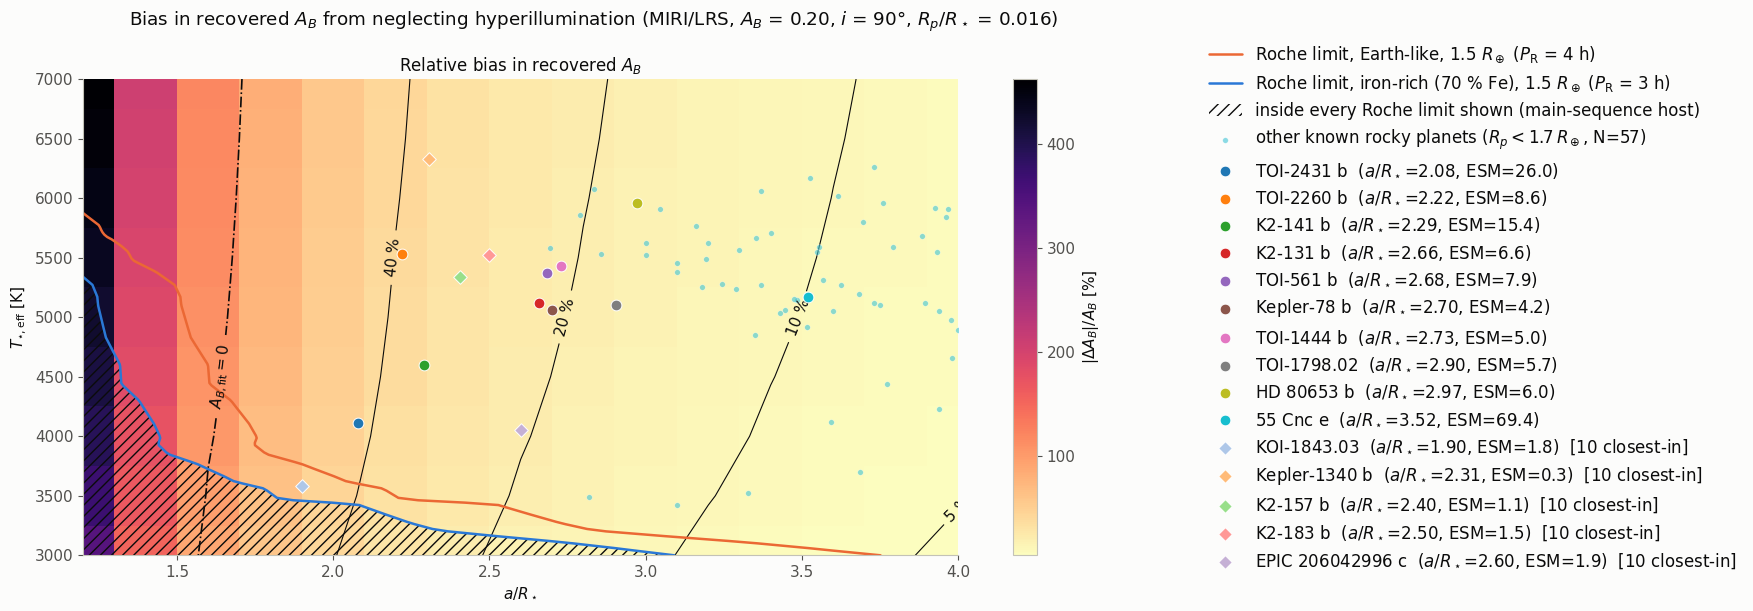

In [3]:
# The bias in recovered A_B is a pure model-degeneracy quantity, so this map is independent of the noise level sigma. The cells are independent -> run in parallel.
# return_chi2: the chi^2 map of the fits is kept for the false-positive map of 2.5, which reuses it instead of refitting.
bias_map_T, chi2_map_T = bias_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", return_chi2=True, **kw)
fig, axs = plot_bias_maps(a_rs_grid, T_eff_grid, bias_map_T, A_B_true, AGG, "st_teff", r"$T_{\star,\rm eff}$ [K]",
               rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, planets=PAPER_PLANETS, show_absolute=show_absolute, show_relative=show_relative,   # panel switches from the setup
               title=rf"Bias in recovered $A_B$ from neglecting hyperillumination ({instrument}, {geom}, $R_p/R_\star$ = {rp_rs_ref:g})")
plt.show()

# bias_map = bias_map_grid(cfg, A_B_true, a_rs_grid, rp_rs_grid, "rp_rs", **kw)
# plot_bias_maps(a_rs_grid, rp_rs_grid, bias_map, A_B_true, AGG, "pl_ratror", r"$R_p/R_\star$",
#                rp_rs_of=lambda y: y, incl=incl_ref, planets=PAPER_PLANETS, show_absolute=show_absolute, show_relative=show_relative,   # panel switches from the setup
#                title=rf"Bias in recovered $A_B$ from neglecting hyperillumination ({instrument}, {geom}, $T_{{\rm eff}}$ = {T_eff_ref:g} K)")

The map shows the bias $\Delta A_B$: an underestimate everywhere, growing towards small $a/R_\star$ and hot hosts (MIRI/LRS and NIRSpec G395H). $A_B$ is fitted within `A_B_FIT_BOUNDS` = $(-2, 1)$; the dash-dot contour marks the fitted $A_B = 0$. The coloured curves are the Roche limits of a 1.5 $R_\oplus$ Earth-like and iron-rich planet (`06_roche_limit.ipynb`); left of the hatched line no such planet survives.

### 1.2 Per-planet decision: does hyperillumination matter for the closest-in rocky planets?

Every planet of `PAPER_PLANETS` fitted at its own geometry and PandExo noise. The bias matters where it exceeds the Fisher $\sigma_{A_B}$, i.e. where the delivered $\sigma_{1\rm min}$ is below the critical noise $\sigma_{1\rm min, crit} = \sigma_{1\rm min}\,|\Delta A_B|/\sigma_{A_B}$; a planet whose $\sigma_{A_B}$ reaches the flat-prior std of `A_B_BOUNDS` is *unconstrained*.

In [4]:
tab_AB = planet_bias_table(cfg, A_B_true, PAPER_PLANETS, sigma_paper, AGG=AGG, **kw)   # cfg supplies filter / stellar grid / albedo model / n_bins / n_orbits; geometry and sigma_1min are per planet; AGG supplies the ESM / Rp rows

# Three-way verdict (bias_verdict): unconstrained where sigma_A_B reaches the flat-prior std of the physical range A_B_BOUNDS; otherwise bias >= 1 sigma needs hyperillumination, else naive OK.
for v in (VERDICT_NEEDS_HI, VERDICT_NAIVE_OK, VERDICT_UNCONSTRAINED, VERDICT_NO_NOISE):
    sel = tab_AB[tab_AB.verdict == v]
    print(f"{len(sel)} of {len(tab_AB)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_AB[["name", "a_rs", "esm", "bias", "sigma", "bias_sigma", *noise_cols(tab_AB), "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))   # noise_cols: sigma_1min and sigma_1min_crit, per detector for a joint fit


1 of 10 needs hyperillum: TOI-2431 b
8 of 10 naive OK: TOI-2260 b, K2-141 b, K2-131 b, TOI-561 b, TOI-1444 b, TOI-1798.02, HD 80653 b, 55 Cnc e
1 of 10 unconstrained: Kepler-78 b
0 of 10 no noise level: -
       name  a_rs   esm     bias   sigma  bias_sigma  sigma_1min  sigma_1min_crit          verdict
 TOI-2431 b  2.08 25.97 -0.05978 0.05308       1.126       62.93            70.86 needs hyperillum
 TOI-2260 b  2.22 8.629 -0.02822  0.1328      0.2126       114.2            24.28         naive OK
   K2-141 b 2.292 15.37 -0.06373 0.08532       0.747       99.24            74.13         naive OK
   K2-131 b  2.66  6.64 -0.04181  0.2053      0.2037       280.3            57.11         naive OK
  TOI-561 b 2.683 7.938 -0.04276  0.1197      0.3571       99.41             35.5         naive OK
Kepler-78 b   2.7 4.229 -0.02025  0.2946     0.06873       202.2            13.89    unconstrained
 TOI-1444 b  2.73 4.981 -0.03632  0.1927      0.1885       145.8            27.48         naive OK
TOI

A planet needs hyperillumination where `bias_sigma` $\ge 1$. The verdicts use the own-geometry fit; the maps assume a central transit and so overstate the bias of inclined planets (`01_albedo_bias.ipynb` §4).

### 1.3 One planet, several instruments: retrieved $A_B$

The $A_B$-only fit of `retrieval_planet` in each of `retrieval_instruments` at its own noise, after Ramirez et al. 2026 (arXiv:2610.22338), Fig. 4. The offset of each point from the injected $A_B$ (dashed) is that band's bias. Bars: Fisher $1\sigma$ and $2\sigma$; hollow: *unconstrained*; half-filled without bars: no noise level. The NIRSpec tuple is one joint fit of both arrays.

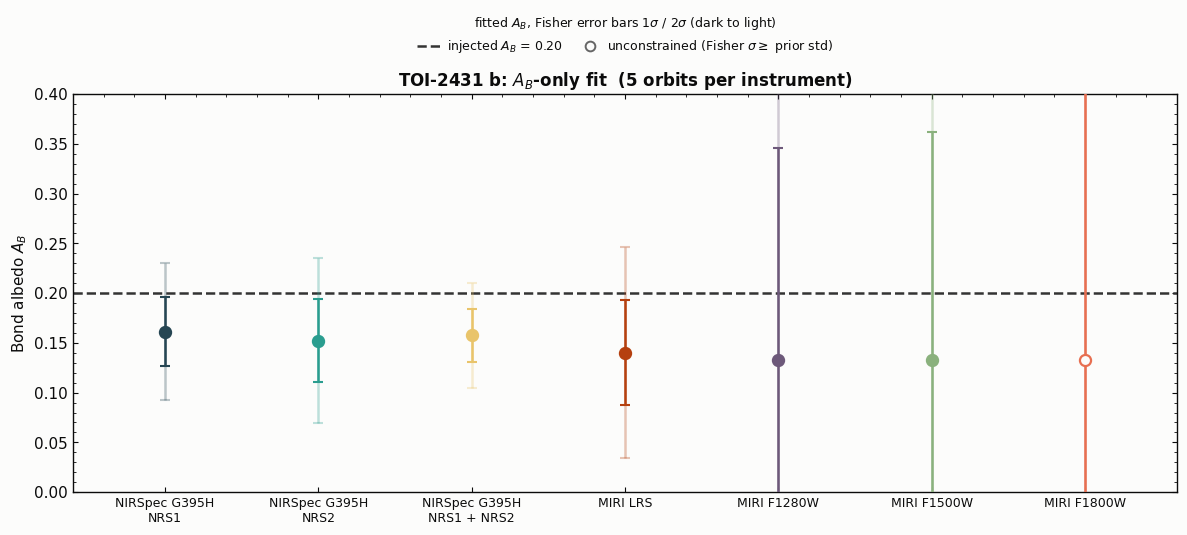

                                     instrument  sigma_1min  A_B_fit  bias_A_B  sigma_A_B  bias_sigma          verdict
                        JWST_NIRSpec.G395H_NRS1       39.13   0.1613  -0.03873    0.03455       1.121 needs hyperillum
                        JWST_NIRSpec.G395H_NRS2       49.41   0.1522  -0.04777    0.04151       1.151 needs hyperillum
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2           -   0.1575  -0.04245    0.02655       1.599 needs hyperillum
                                       MIRI/LRS       62.93   0.1402  -0.05978    0.05308       1.126 needs hyperillum
                                    MIRI/F1280W       247.2    0.133  -0.06701     0.2132      0.3143         naive OK
                                    MIRI/F1500W         264   0.1326  -0.06744     0.2291      0.2944         naive OK
                                    MIRI/F1800W       396.2   0.1325  -0.06748     0.3459      0.1951    unconstrained


In [5]:
# One planet on several instruments: fitted A_B +- Fisher sigma per instrument, for a hyperillumination truth injected at A_B_inj.
retrieval_planet = hi_planets_by_name("TOI-2431 b")
retrieval_instruments = JWST_RETRIEVALS   # sorted by wavelength (the plots of 1.3, 1.4, 2.3, 2.4 and 2.6 keep this order); the tuple in it is one joint fit of the two NIRSpec arrays
A_B_inj = A_B_true   # injected Bond albedo; n_orbits and the band albedo model come from cfg

tab_inst_AB = instrument_retrievals(cfg, retrieval_planet, retrieval_instruments, A_B_inj, **kw)
sigma_inst = tab_inst_AB.attrs["sigma_1min"]   # {detector: ppm}; 2.3 reuses these noise levels
fig, ax = plot_instrument_retrievals(tab_inst_AB, title=f"{retrieval_planet.name}: $A_B$-only fit  ({n_orbits} orbits per instrument)")
plt.show()
print(tab_inst_AB.drop(columns=["F_fit", "sigma_F", "chi2"]).to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))   # chi2: kept for 2.6

### 1.4 One planet, several instruments: occultation depth of the fit

The occultation depth of each fit of 1.3 (no refit, run 1.3 first) against that of the truth (dashed segment per band), with Fisher $1\sigma$ / $2\sigma$ bars. Where the fitted depth matches the truth while $A_B$ is biased, the occultation alone does not reveal the wrong model. The joint NIRSpec fit has no single depth and is left out.

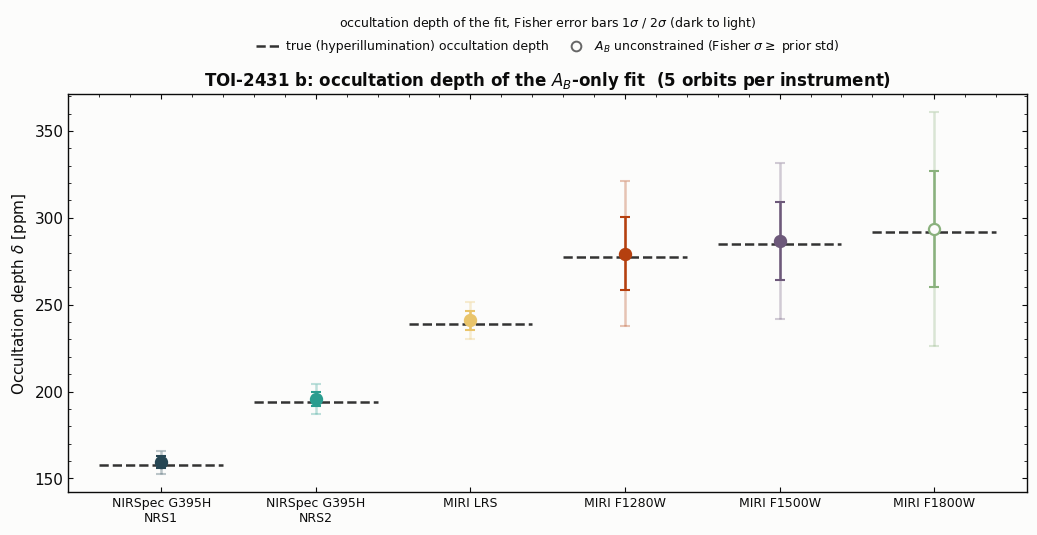

             instrument  A_B_fit  depth_true  depth_fit  bias_depth  sigma_depth  depth_bias_sigma  bias_sigma          verdict
JWST_NIRSpec.G395H_NRS1   0.1613         158      159.3       1.275        3.374             0.378       1.121 needs hyperillum
JWST_NIRSpec.G395H_NRS2   0.1522         194      195.7        1.71        4.234            0.4039       1.151 needs hyperillum
               MIRI/LRS   0.1402         239        241       2.014         5.36            0.3758       1.126 needs hyperillum
            MIRI/F1280W    0.133       277.6      279.4       1.823        20.99           0.08687      0.3143         naive OK
            MIRI/F1500W   0.1326         285      286.6       1.673         22.4           0.07471      0.2944         naive OK
            MIRI/F1800W   0.1325       292.1      293.5       1.492         33.6           0.04439      0.1951    unconstrained


In [6]:
# Occultation depth of each A_B-only fit of 1.3 (no refit), exact at mid-occultation, against the true hyperillumination depth on the same instrument.
tab_depth_AB = instrument_depths(cfg, retrieval_planet, tab_inst_AB, **kw)   # same cfg / planet / kw as the fits of 1.3
fig, ax = plot_instrument_retrievals(tab_depth_AB, quantity="depth", title=f"{retrieval_planet.name}: occultation depth of the $A_B$-only fit  ({n_orbits} orbits per instrument)")
plt.show()
depth_cols = ["instrument", "A_B_fit", "F_fit", "depth_true", "depth_fit", "bias_depth", "sigma_depth", "depth_bias_sigma", "bias_sigma", "verdict"]   # bias_sigma / verdict: those of A_B, for comparison
print(tab_depth_AB[[c for c in depth_cols if c != "F_fit"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

### 1.5 All three detectors in one fit: NIRSpec + MIRI/LRS

NRS1, NRS2 and MIRI/LRS fitted as one (shared $A_B$, a baseline per detector) next to MIRI/LRS alone and the joint NIRSpec fit, for `multi_planets`. The tables compare $\sigma_{A_B}$ and the `excess` of the combined $\chi^2_{\min}$ over the sum of the parts, which measures how much the bias differs between the bands.

In [7]:
# NRS1 + NRS2 + MIRI/LRS as ONE fit (shared A_B, a baseline per detector), next to its parts
multi_planets = ("TOI-2431 b", "K2-141 b")
multi_instruments = ["MIRI/LRS", tuple(JWST_BANDS[:2]), (*JWST_BANDS[:2], "MIRI/LRS")]
MULTI_LABEL = dict(zip([instrument_key(ins) for ins in multi_instruments], ("MIRI/LRS", "joint NIRSpec", "NIRSpec + LRS")))

tab_multi_AB = {nm: instrument_retrievals(cfg, hi_planets_by_name(nm), multi_instruments, A_B_true, **kw) for nm in multi_planets}
for nm, t in tab_multi_AB.items():
    t = t.assign(mode=t["instrument"].map(MULTI_LABEL), lnB_mean=0.5 * t["chi2"])
    print(nm)
    print(t[["mode", "A_B_fit", "bias_A_B", "sigma_A_B", "bias_sigma", "chi2", "lnB_mean", "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    c = t.set_index("mode")["chi2"]
    print(f"   chi2_min: combined {c['NIRSpec + LRS']:.2f}, sum of the parts {c['MIRI/LRS'] + c['joint NIRSpec']:.2f}  ->  excess {c['NIRSpec + LRS'] - c['MIRI/LRS'] - c['joint NIRSpec']:.2f}\n")

TOI-2431 b
         mode  A_B_fit  bias_A_B  sigma_A_B  bias_sigma  chi2  lnB_mean          verdict
     MIRI/LRS   0.1402  -0.05978    0.05308       1.126 12.64     6.318 needs hyperillum
joint NIRSpec   0.1575  -0.04245    0.02655       1.599 11.58     5.792 needs hyperillum
NIRSpec + LRS    0.154  -0.04598    0.02374       1.937 24.31     12.15 needs hyperillum
   chi2_min: combined 24.31, sum of the parts 24.22  ->  excess 0.09

K2-141 b
         mode  A_B_fit  bias_A_B  sigma_A_B  bias_sigma  chi2  lnB_mean          verdict
     MIRI/LRS   0.1363  -0.06373    0.08532       0.747 4.114     2.057         naive OK
joint NIRSpec   0.1576  -0.04241    0.03724       1.139 5.157     2.578 needs hyperillum
NIRSpec + LRS   0.1541  -0.04589    0.03412       1.345 9.324     4.662 needs hyperillum
   chi2_min: combined 9.32, sum of the parts 9.27  ->  excess 0.05



## 2. Joint bias in $A_B$ and $F$ (`naive_redist`)

The analyses of section 1 for the joint fit of $A_B$, $F \in [0, 0.5]$ and the baseline. The truth has $F = 0$, so any fitted $F$ is heat redistribution the data do not contain. Below $i = 90°$, cells without an occultation are greyed out: there $A_B$ and $F$ are degenerate.

### 2.1 In which regimes does hyperillumination matter? Bias maps over (a/Rs, T_eff)

occulting, non-railed cells: 135 of 135;  Delta A_B in [-0.956, -0.031] = [-478.2, -15.3] % of A_B,  F in [0.0012, 0.0196]
fitted A_B < 0 in 44 of 135 cells;  railed: 0,  without occultation: 0


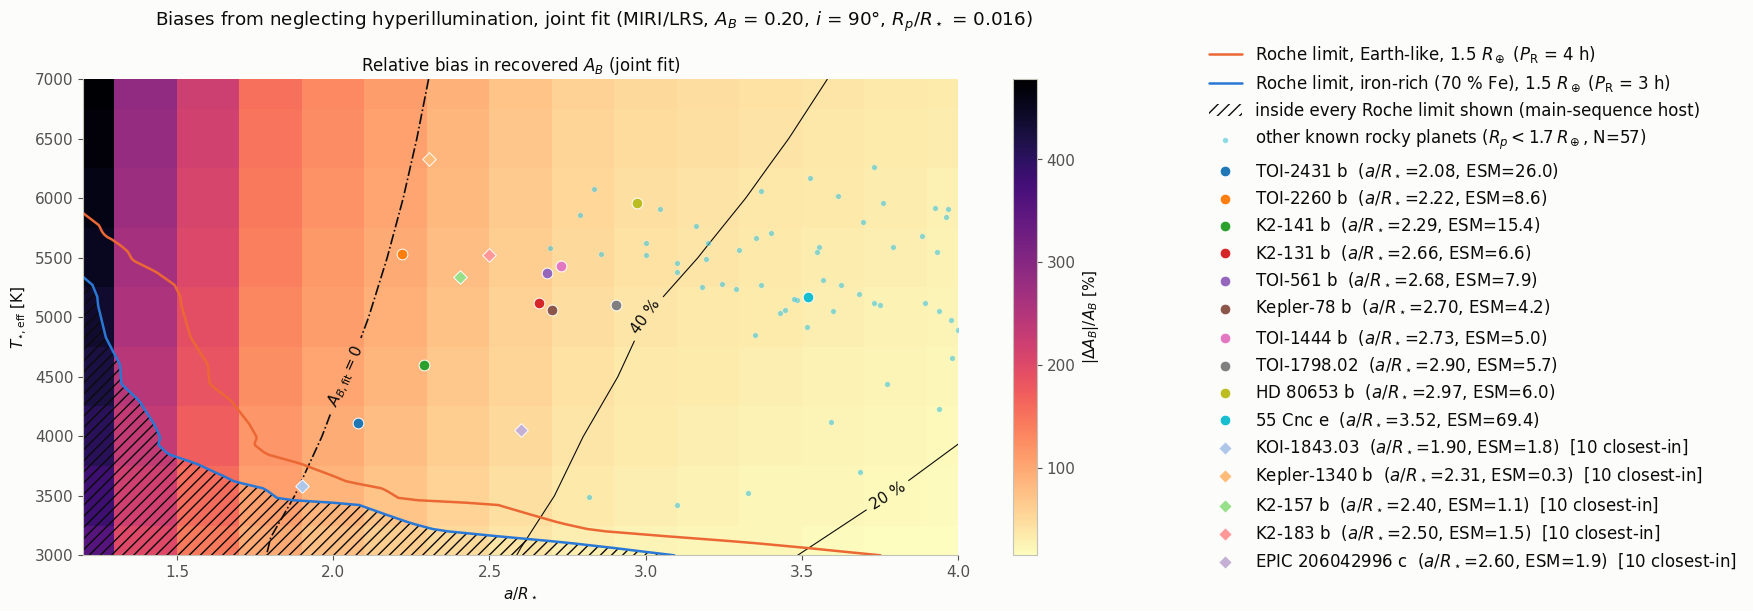

In [8]:
# The biases are pure model-degeneracy quantities, so these maps are independent of the noise level sigma. The cells are independent -> run in parallel.
# return_chi2: the chi^2 map of the fits is kept for the false-positive map of 2.5, which reuses it instead of refitting.
bias_map_JT, F_map_JT, chi2_map_JT = bias_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", redist=True, return_chi2=True, **kw)
fig, axs = plot_bias_maps(a_rs_grid, T_eff_grid, bias_map_JT, A_B_true, AGG, "st_teff", r"$T_{\star,\rm eff}$ [K]",
               rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, F_map=F_map_JT, planets=PAPER_PLANETS,
               show_absolute=show_absolute, show_relative=show_relative, show_F=False,   # panel switches from the setup; show_F=True adds the fitted-F panel
               title=rf"Biases from neglecting hyperillumination, joint fit ({instrument}, {geom}, $R_p/R_\star$ = {rp_rs_ref:g})")
plt.show()

# bias_map, F_map = bias_map_grid(cfg, A_B_true, a_rs_grid, rp_rs_grid, "rp_rs", redist=True, **kw)
# plot_bias_maps(a_rs_grid, rp_rs_grid, bias_map, A_B_true, AGG, "pl_ratror", r"$R_p/R_\star$",
#                rp_rs_of=lambda y: y, incl=incl_ref, F_map=F_map, planets=PAPER_PLANETS,
#                show_absolute=show_absolute, show_relative=show_relative, show_F=False,   # panel switches from the setup; show_F=True adds the fitted-F panel
#                title=rf"Biases from neglecting hyperillumination, joint fit ({instrument}, {geom}, $T_{{\rm eff}}$ = {T_eff_ref:g} K)")

The joint map has the shape of 1.1 with every contour moved to larger $a/R_\star$: freeing $F$ lets the fit trade albedo for a spurious nightside, so the $A_B$ bias grows and the fitted $F$ is positive. `show_F=True` adds the map of $F$.

### 2.2 Per-planet decision: does the biased $A_B$ (and the spurious $F$) matter for the closest-in rocky planets?

As 1.2, for the joint fit. The verdict refers to $A_B$ (`quantity="F"` puts it on $F$); *unconstrained* uses the flat-prior std of `A_B_BOUNDS` and `F_BOUNDS`.

In [9]:
# redist=True -> the joint (A_B, F) fit; quantity defaults to "A_B", so bias / sigma / bias_sigma / sigma_1min_crit all refer to the albedo bias (pass quantity="F" for the spurious redistribution instead).
tab_redist = planet_bias_table(cfg, A_B_true, PAPER_PLANETS, sigma_paper, redist=True, AGG=AGG, **kw)
title_tail = f"({instrument}, $A_B$ = {A_B_true:.2f}, {n_orbits} orbits, {n_bins} bins)"

# Three-way verdict (bias_verdict): unconstrained where sigma_A_B reaches the flat-prior std of the physical range A_B_BOUNDS; otherwise bias >= 1 sigma needs hyperillumination, else naive OK.
for v in (VERDICT_NEEDS_HI, VERDICT_NAIVE_OK, VERDICT_UNCONSTRAINED, VERDICT_NO_NOISE):
    sel = tab_redist[tab_redist.verdict == v]
    print(f"{len(sel)} of {len(tab_redist)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_redist[["name", "a_rs", "esm", "bias_A_B", "sigma_A_B", "F_fit", "sigma_F", "bias_sigma", *noise_cols(tab_redist), "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))


3 of 10 needs hyperillum: TOI-2431 b, K2-141 b, 55 Cnc e
6 of 10 naive OK: TOI-2260 b, K2-131 b, TOI-561 b, TOI-1444 b, TOI-1798.02, HD 80653 b
1 of 10 unconstrained: Kepler-78 b
0 of 10 no noise level: -
       name  a_rs   esm  bias_A_B  sigma_A_B    F_fit  sigma_F  bias_sigma  sigma_1min  sigma_1min_crit          verdict
 TOI-2431 b  2.08 25.97   -0.1691    0.07049 0.005813 0.002416       2.399       62.93              151 needs hyperillum
 TOI-2260 b  2.22 8.629     -0.16     0.1964 0.003684 0.004415      0.8145       114.2            93.05         naive OK
   K2-141 b 2.292 15.37   -0.1561     0.1119 0.003967 0.003064       1.396       99.24            138.5 needs hyperillum
   K2-131 b  2.66  6.64   -0.1092     0.2748 0.002726  0.00736      0.3972       280.3            111.3         naive OK
  TOI-561 b 2.683 7.938   -0.1127     0.1605 0.002524 0.003883      0.7022       99.41             69.8         naive OK
Kepler-78 b   2.7 4.229    -0.109     0.4643 0.003272  0.01333      0

Compared with 1.2, the joint $A_B$ bias is larger for every planet and part of the misfit goes into a spurious $F$; that can turn *naive OK* into *needs hyperillumination*, although $\sigma_{A_B}$ grows as well ($A_B$–$F$ degeneracy).

The table of 2.2 as a figure: the fitted $A_B$ per planet with Fisher $1\sigma$ / $2\sigma$ bars, the joint fit (squares) next to the $A_B$-only fit of 1.2 (circles); hollow: *unconstrained*. The gap between square and circle is the extra bias from freeing $F$.

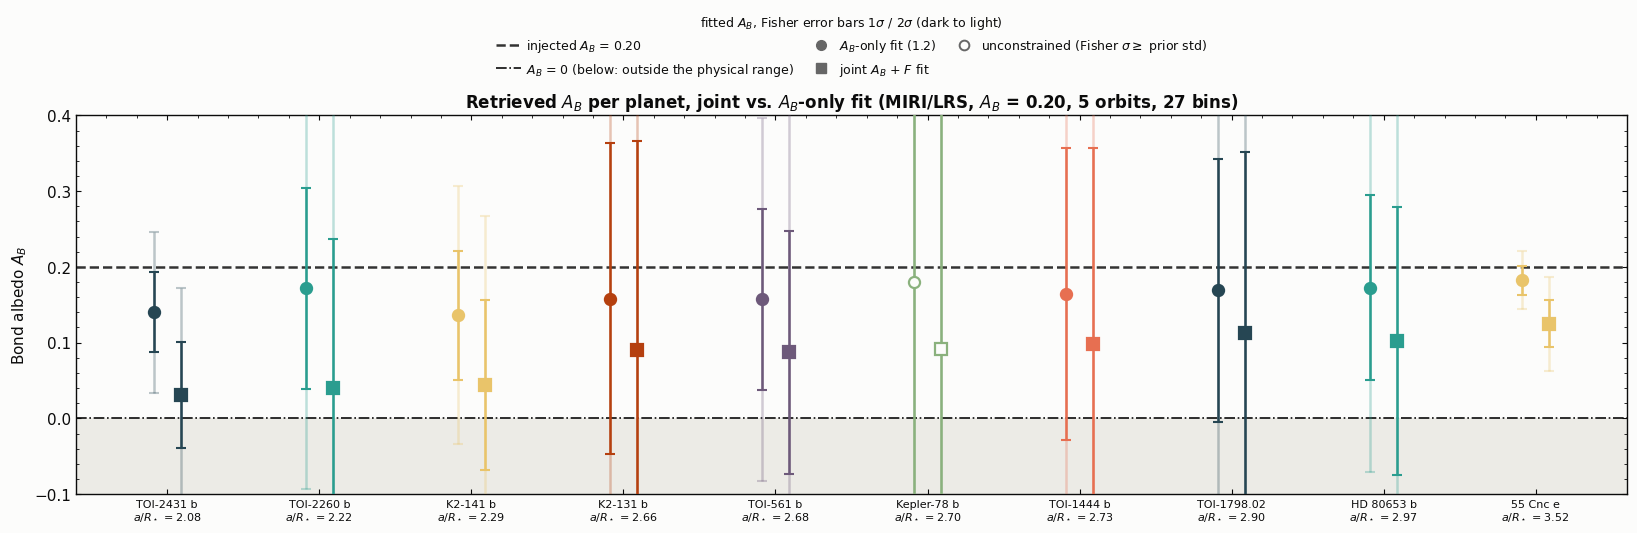

In [10]:
# 2.2 as a retrieval plot (one position per planet, on this instrument): the joint fit of this section next to the A_B-only fit of 1.2, for every planet of the list.
fig, ax = plot_planet_retrievals({"$A_B$-only fit (1.2)": tab_AB, "joint $A_B$ + $F$ fit": tab_redist}, planets=PAPER_PLANETS,
                                 title=f"Retrieved $A_B$ per planet, joint vs. $A_B$-only fit {title_tail}")
plt.show()

### 2.3 One planet, several instruments: retrieved $A_B$ with the joint fit

As 1.3 (run it first): the joint fit (squares) next to the $A_B$-only fit (circles), at the same planet, instruments, $A_B$ and noise. The table adds the spurious $F$ and its Fisher $\sigma$.

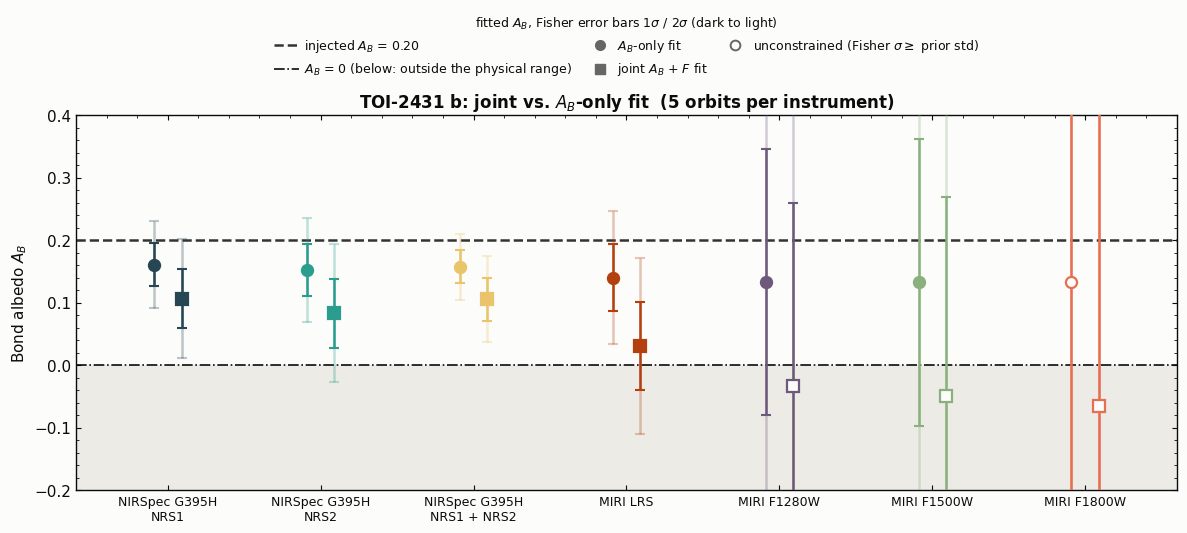

                                     instrument  sigma_1min  A_B_fit  bias_A_B  sigma_A_B    F_fit  sigma_F  bias_sigma          verdict
                        JWST_NIRSpec.G395H_NRS1       39.13   0.1068  -0.09318    0.04774  0.01943  0.00893       1.952 needs hyperillum
                        JWST_NIRSpec.G395H_NRS2       49.41  0.08325   -0.1167    0.05504  0.01279 0.005432       2.121 needs hyperillum
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2           -   0.1057   -0.0943    0.03461  0.01402 0.004748       2.724 needs hyperillum
                                       MIRI/LRS       62.93  0.03086   -0.1691    0.07049 0.005813 0.002416       2.399 needs hyperillum
                                    MIRI/F1280W       247.2 -0.03383   -0.2338     0.2932 0.002514 0.003438      0.7976    unconstrained
                                    MIRI/F1500W         264 -0.04941   -0.2494     0.3183 0.002005 0.002866      0.7837    unconstrained
                                    MIRI/

In [11]:
# The joint (A_B, F) fit per instrument, set next to the A_B-only fit of 1.3 (same planet, instruments, injected A_B and noise levels).
tab_inst_J = instrument_retrievals(cfg, retrieval_planet, retrieval_instruments, A_B_inj, redist=True, sigma_1min=sigma_inst, **kw)
fig, ax = plot_instrument_retrievals({"$A_B$-only fit": tab_inst_AB, "joint $A_B$ + $F$ fit": tab_inst_J},
                                     title=f"{retrieval_planet.name}: joint vs. $A_B$-only fit  ({n_orbits} orbits per instrument)")
plt.show()
print(tab_inst_J.drop(columns=["chi2"]).to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))   # chi2: kept for 2.6

### 2.4 One planet, several instruments: occultation depth of the joint fit

As 1.4 for the joint fits of 2.3 (squares) next to the $A_B$-only fits (circles); run 1.3, 1.4 and 2.3 first. `depth_bias_sigma` against `bias_sigma` shows whether freeing $F$ moves the depth away from the truth.

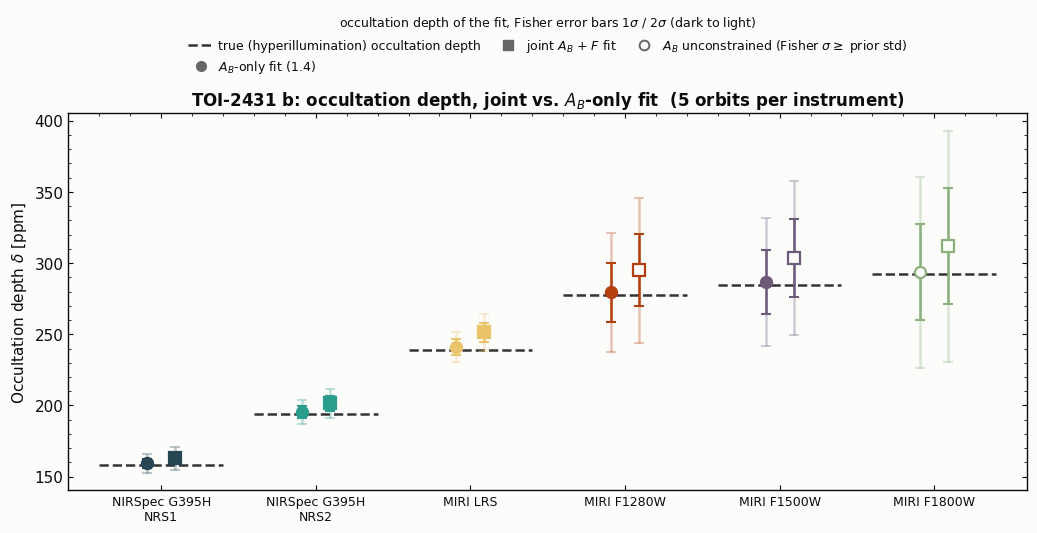

             instrument  A_B_fit    F_fit  depth_true  depth_fit  bias_depth  sigma_depth  depth_bias_sigma  bias_sigma          verdict
JWST_NIRSpec.G395H_NRS1   0.1068  0.01943         158      162.8       4.776        4.032             1.185       1.952 needs hyperillum
JWST_NIRSpec.G395H_NRS2  0.08325  0.01279         194      201.5       7.511        5.094             1.475       2.121 needs hyperillum
               MIRI/LRS  0.03086 0.005813         239      251.4       12.35         6.48             1.906       2.399 needs hyperillum
            MIRI/F1280W -0.03383 0.002514       277.6        295       17.42        25.42            0.6851      0.7976    unconstrained
            MIRI/F1500W -0.04941 0.002005         285      303.5       18.53        27.14            0.6829      0.7837    unconstrained
            MIRI/F1800W -0.06517 0.001575       292.1      311.7       19.63        40.73             0.482      0.5459    unconstrained


In [12]:
# Occultation depth of each joint fit of 2.3 (no refit), set next to the A_B-only depths of 1.4.
tab_depth_J = instrument_depths(cfg, retrieval_planet, tab_inst_J, **kw)
fig, ax = plot_instrument_retrievals({"$A_B$-only fit (1.4)": tab_depth_AB, "joint $A_B$ + $F$ fit": tab_depth_J}, quantity="depth",
                                     title=f"{retrieval_planet.name}: occultation depth, joint vs. $A_B$-only fit  ({n_orbits} orbits per instrument)")
plt.show()
print(tab_depth_J[depth_cols].to_string(index=False, float_format=lambda v: f"{v:.4g}"))

### 2.5 Where does the spurious $F$ become a false-positive atmosphere? Critical noise map over (a/Rs, T_eff)

A significant $F > 0$ would be reported as heat transport, by an atmosphere or a molten interior. Its expected significance is $\sqrt{\Delta\chi^2_F}$, with $\Delta\chi^2_F = \chi^2(A_B\text{-only fit}) - \chi^2(\text{joint fit})$ on the noiseless truth (Asimov data set, Cowan et al. 2011), read from the $\chi^2$ maps of 1.1 and 2.1. The map shows the critical noise $\sigma_{1\,\rm min,\,crit} = \sigma_{1\,\rm min}\sqrt{\Delta\chi^2_F}/z$ below which the spurious $F$ reaches `z_false` σ in `n_orbits`; it scales as $(R_p/R_\star)^2$.

occulting, non-railed cells: 135 of 135;  sigma_1min,crit (2 sigma, 5 orbits) in [4.7, 493.1] ppm;  sqrt(dchi2_F) at sigma_1min = 100 ppm in [0.09, 9.86] sigma
railed: 0,  without occultation: 0


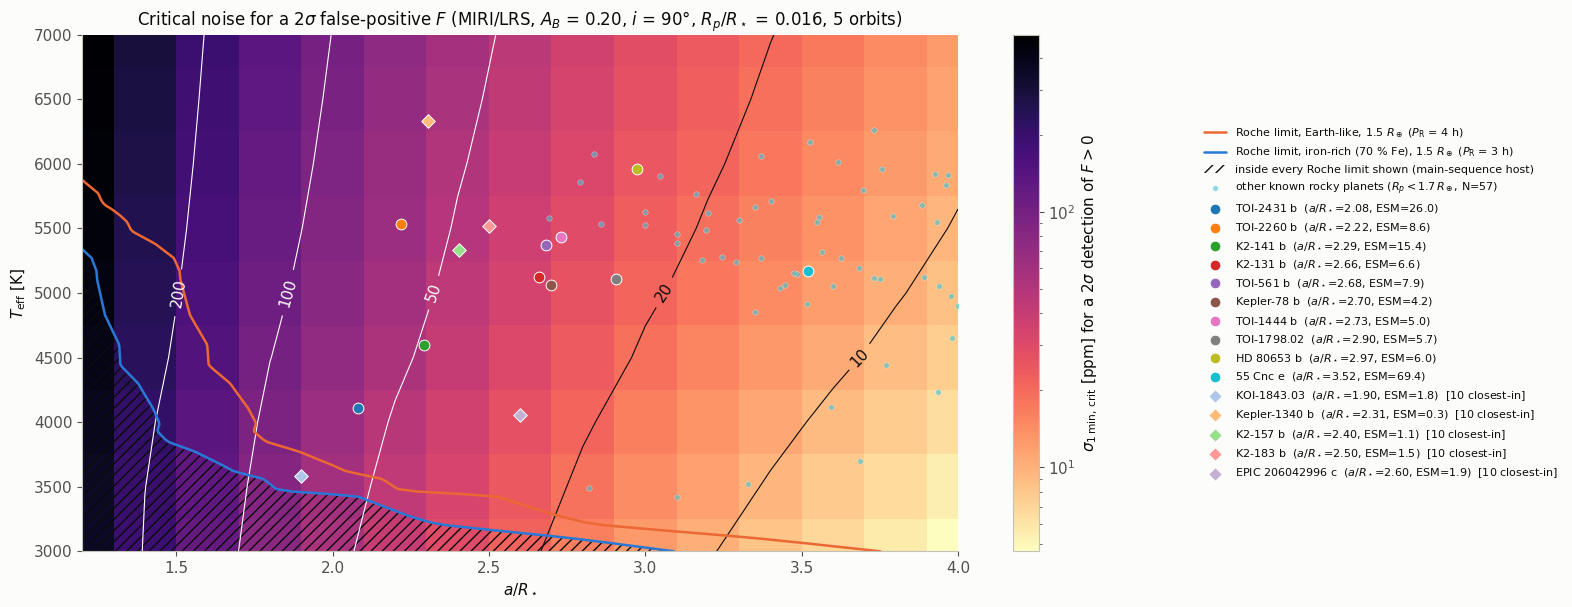

In [13]:
# Likelihood-ratio statistic of the spurious F per map cell: dchi2_F = chi2(A_B-only fit) - chi2(joint fit). No refit: fits= takes the chi^2 maps of 1.1 and 2.1 (same result as refitting).
z_false = 2.   # the false positive's significance [sigma] that the critical noise refers to
dchi2_map_FT, F_map_FT = false_F_map_grid(cfg, A_B_true, a_rs_grid, T_eff_grid, "T_s", fits=(chi2_map_T, chi2_map_JT, F_map_JT), **kw)
sig_crit_FT = plot_false_F_map(a_rs_grid, T_eff_grid, dchi2_map_FT, cfg, AGG, "st_teff", r"$T_{\rm eff}$ [K]", rp_rs_of=lambda y: np.full_like(y, rp_rs_ref), incl=incl_ref, z=z_false, planets=PAPER_PLANETS,
                               title=rf"Critical noise for a {z_false:g}$\sigma$ false-positive $F$ ({instrument}, {geom}, $R_p/R_\star$ = {rp_rs_ref:g}, {n_orbits} orbits)")
plt.show()

### 2.6 Per-planet and per-instrument false positives: the spurious $F$ at each planet's own geometry and noise

The test of 2.5 for the planets of 2.2 (first cell) and for `retrieval_planet` in the instruments of 2.3 (second cell); no refit, so run those first. Per row: $z_F = \sqrt{\Delta\chi^2_F}$ against `z_false`, the critical noise, the observing time $t_{\rm crit} = t_{\rm obs}(z/z_F)^2$ at which $F$ crosses the threshold, and the nightside temperature the false positive implies (Kreidberg & Loeb 2016, eq. 1).

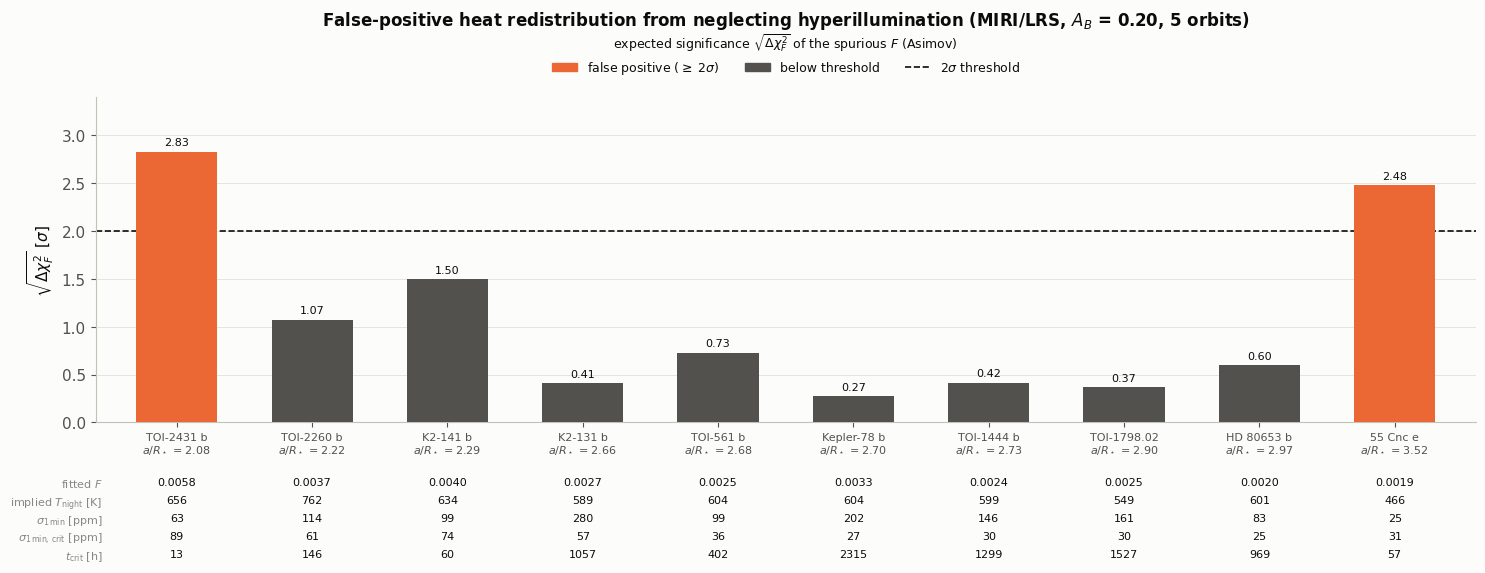

2 of 10 false positive: TOI-2431 b, 55 Cnc e
8 of 10 below threshold: TOI-2260 b, K2-141 b, K2-131 b, TOI-561 b, Kepler-78 b, TOI-1444 b, TOI-1798.02, HD 80653 b
       name  a_rs   esm  A_B_fit_naive  A_B_fit    F_fit  T_night_fit  dchi2_F    z_F  sigma_1min  sigma_1min_crit  noise_margin  t_obs  t_crit         verdict
 TOI-2431 b  2.08 25.97         0.1402  0.03086 0.005813        656.4    8.013  2.831       62.93            89.06         1.415   26.9   13.43  false positive
 TOI-2260 b  2.22 8.629         0.1718  0.04005 0.003684        761.7    1.155  1.075       114.2             61.4        0.5374   42.3   146.4 below threshold
   K2-141 b 2.292 15.37         0.1363  0.04388 0.003967        633.9     2.24  1.497       99.24            74.26        0.7483  33.64   60.07 below threshold
   K2-131 b  2.66  6.64         0.1582  0.09085 0.002726          589   0.1677 0.4096       280.3            57.41        0.2048  44.32    1057 below threshold
  TOI-561 b 2.683 7.938         0.1572

In [14]:
# The planets of 2.2 at their own geometry and PandExo noise (sigma_paper): both fits, dchi2_F and the decision columns. No refit: fits= reuses the tables of 1.2 and 2.2 (same result as refitting).
tab_FP = planet_false_F_table(cfg, A_B_true, PAPER_PLANETS, sigma_paper, z=z_false, AGG=AGG, fits=(tab_AB, tab_redist), **kw)
fig, ax = plot_planet_false_F_bars(tab_FP, planets=PAPER_PLANETS, title=f"False-positive heat redistribution from neglecting hyperillumination ({instrument}, $A_B$ = {A_B_true:.2f}, {n_orbits} orbits)")   # for a joint fit the noise rows are per detector
plt.show()
for v in (FALSE_POSITIVE, NO_FALSE_POSITIVE):
    sel = tab_FP[tab_FP.verdict == v]
    print(f"{len(sel)} of {len(tab_FP)} {v}: {', '.join(sel.name) if len(sel) else '-'}")
print(tab_FP[["name", "a_rs", "esm", "A_B_fit_naive", "A_B_fit", "F_fit", "T_night_fit", "dchi2_F", "z_F", *noise_cols(tab_FP), "noise_margin", "t_obs", "t_crit", "verdict"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4g}"))


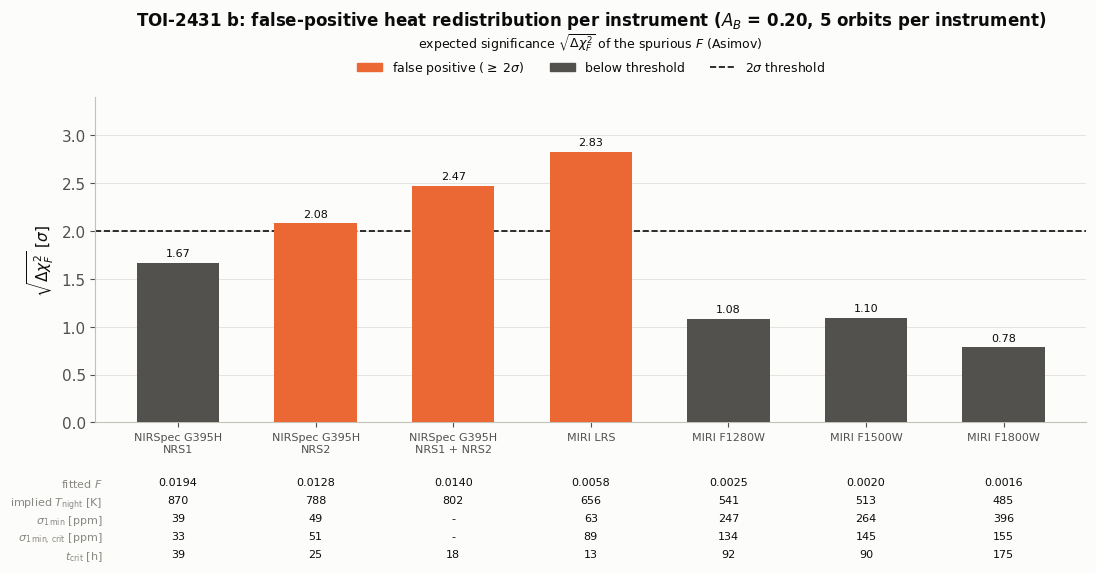

                                     instrument  A_B_fit_naive  A_B_fit    F_fit  T_night_fit  dchi2_F    z_F  sigma_1min  sigma_1min_crit  noise_margin  t_crit         verdict
                        JWST_NIRSpec.G395H_NRS1         0.1613   0.1068  0.01943        869.6    2.781  1.668       39.13            32.63        0.8339   38.69 below threshold
                        JWST_NIRSpec.G395H_NRS2         0.1522  0.08325  0.01279        788.3    4.341  2.083       49.41            51.47         1.042   24.79  false positive
JWST_NIRSpec.G395H_NRS1+JWST_NIRSpec.G395H_NRS2         0.1575   0.1057  0.01402        801.7    6.118  2.474           -                -         1.237   17.59  false positive
                                       MIRI/LRS         0.1402  0.03086 0.005813        656.4    8.013  2.831       62.93            89.06         1.415   13.43  false positive
                                    MIRI/F1280W          0.133 -0.03383 0.002514        540.9    1.172  1.082      

In [15]:
# retrieval_planet on the instruments of 1.3 (same noise levels, sigma_inst), including the joint NRS1 + NRS2 fit. No refit: fits= reuses the tables of 1.3 and 2.3 (same result as refitting).
tab_FP_inst = instrument_false_F(cfg, retrieval_planet, retrieval_instruments, A_B_inj, z=z_false, sigma_1min=sigma_inst, fits=(tab_inst_AB, tab_inst_J), **kw)
fig, ax = plot_false_F_bars(tab_FP_inst, title=f"{retrieval_planet.name}: false-positive heat redistribution per instrument ($A_B$ = {A_B_inj:.2f}, {n_orbits} orbits per instrument)")
plt.show()
print(tab_FP_inst[["instrument", "A_B_fit_naive", "A_B_fit", "F_fit", "T_night_fit", "dchi2_F", "z_F", "sigma_1min", "sigma_1min_crit", "noise_margin", "t_crit", "verdict"]]
      .to_string(index=False, na_rep="-", float_format=lambda v: f"{v:.4g}"))


### 2.7 All three detectors in one fit: the multi-band consistency of $F$

The joint fits of 2.3 find a different $F$ in every band, whereas a uniform nightside, as the model assumes, has the same $F$ in every band. Here NRS1, NRS2 and MIRI/LRS share one $A_B$ and one $F$ (a baseline per detector), for the planets of 1.5 (run it first): $z_F$ against the $A_B$-only fits of 1.5, and the `excess` of the combined $\chi^2_{\min}$ over the sum of the parts, which measures that inconsistency.

In [16]:
tab_multi_J = {nm: instrument_retrievals(cfg, hi_planets_by_name(nm), multi_instruments, A_B_true, redist=True, sigma_1min=tab_multi_AB[nm].attrs["sigma_1min"], **kw) for nm in multi_planets}
for nm, t in tab_multi_J.items():
    t = t.assign(mode=t["instrument"].map(MULTI_LABEL), z_F=np.sqrt(np.clip(tab_multi_AB[nm]["chi2"].to_numpy() - t["chi2"].to_numpy(), 0., None)), half_chi2=0.5 * t["chi2"])
    print(nm)
    print(t[["mode", "A_B_fit", "bias_A_B", "sigma_A_B", "bias_sigma", "F_fit", "z_F", "chi2", "half_chi2", "verdict"]].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    c = t.set_index("mode")["chi2"]
    print(f"   chi2_min of the fit with redistribution: combined {c['NIRSpec + LRS']:.2f}, sum of the parts {c['MIRI/LRS'] + c['joint NIRSpec']:.2f}  ->  excess {c['NIRSpec + LRS'] - c['MIRI/LRS'] - c['joint NIRSpec']:.2f}"
          f"  (one F for all bands; chi2 / 2 is the likelihood part of ln B against the extended source, without the Occam term of the F prior)\n")

TOI-2431 b
         mode  A_B_fit  bias_A_B  sigma_A_B  bias_sigma    F_fit   z_F  chi2  half_chi2          verdict
     MIRI/LRS  0.03086   -0.1691    0.07049       2.399 0.005813 2.831 4.623      2.311 needs hyperillum
joint NIRSpec   0.1057   -0.0943    0.03461       2.724  0.01402 2.474 5.466      2.733 needs hyperillum
NIRSpec + LRS   0.1155  -0.08448      0.028       3.017 0.006571 2.993 15.35      7.674 needs hyperillum
   chi2_min of the fit with redistribution: combined 15.35, sum of the parts 10.09  ->  excess 5.26  (one F for all bands; chi2 / 2 is the likelihood part of ln B against the extended source, without the Occam term of the F prior)

K2-141 b
         mode  A_B_fit  bias_A_B  sigma_A_B  bias_sigma    F_fit   z_F  chi2  half_chi2          verdict
     MIRI/LRS  0.04388   -0.1561     0.1119       1.396 0.003967 1.497 1.874     0.9371 needs hyperillum
joint NIRSpec   0.1156  -0.08443    0.04763       1.773  0.01007 1.495 2.922      1.461 needs hyperillum
NIRSpec + LRS